In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
fb = pd.read_csv('fb_stock_prices_2018.csv')
fb.head(2)

,date,open,high,low,close,volume
0,2/01/2018,177.68,181.58,177.55,181.42,18151903
1,3/01/2018,181.88,184.78,181.33,184.67,16886563


In [4]:
# the above error is because the date is in datetime format and we dont have year separate to finx this:
#panda's conversion function to date time convert our date column to DateTime
fb['date'] = pd.to_datetime(fb['date'], format='mixed')
fb['year'] = fb['date'].dt.year
fb['month'] = fb['date'].dt.month

fb.head(2)

,date,open,high,low,close,volume,year,month
0,2018-02-01,177.68,181.58,177.55,181.42,18151903,2018,2
1,2018-03-01,181.88,184.78,181.33,184.67,16886563,2018,3


# Plotting lines
Line plots help us see how a variable changes over time. 

<Axes: title={'center': 'Evolution of Facebook Open Price'}, xlabel='date'>

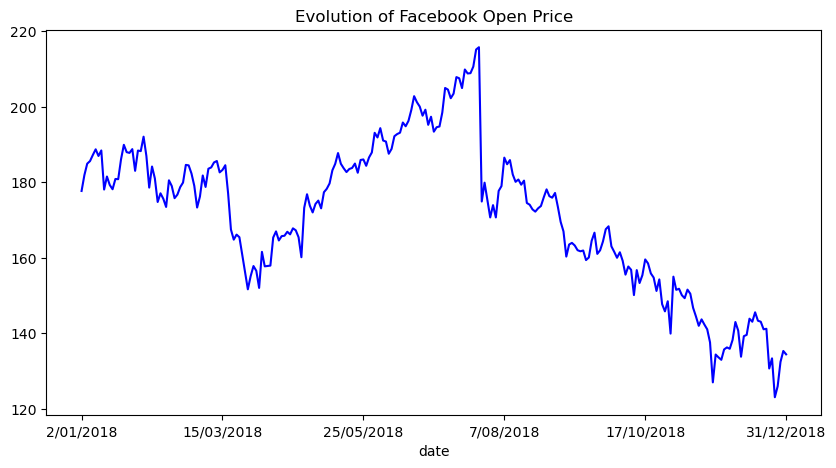

In [5]:
fb2 = pd.read_csv(
    'fb_stock_prices_2018.csv', index_col='date', parse_dates=True
)
fb2.plot(
    kind='line',
    y='open',
    figsize=(10, 5),
    color='blue',
    linestyle='solid',
    legend=False,
    title='Evolution of Facebook Open Price'
)

array([[<Axes: xlabel='date'>, <Axes: xlabel='date'>],
       [<Axes: xlabel='date'>, <Axes: xlabel='date'>],
       [<Axes: xlabel='date'>, <Axes: xlabel='date'>]], dtype=object)

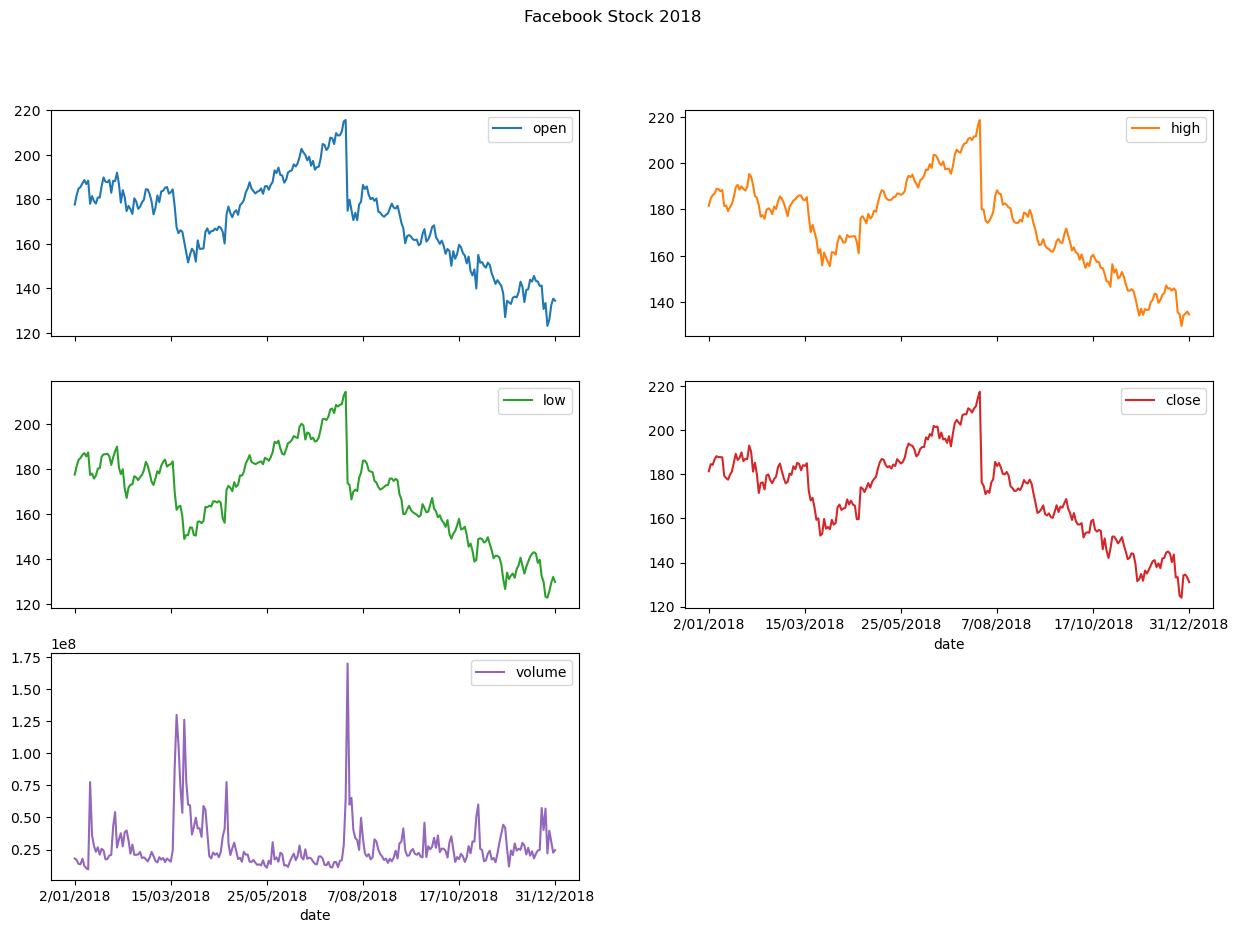

In [6]:
#subplots
fb2.plot(
    kind='line',
    subplots=True,
    layout=(3,2),
    figsize=(15,10),
    title='Facebook Stock 2018'
)

# Scatter plots

We can pass in a string specifying the style of the plot. This is of the form '[color][marker][linestyle]'. For example, we can make a black dashed line with 'k--' or a red scatter plot with 'ro':

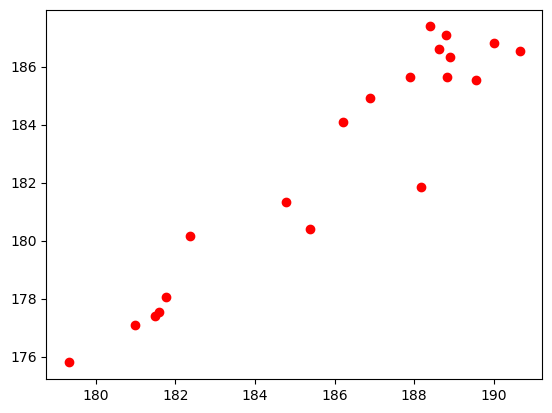

In [7]:
plt.plot('high', 'low', 'ro', data=fb.head(20))

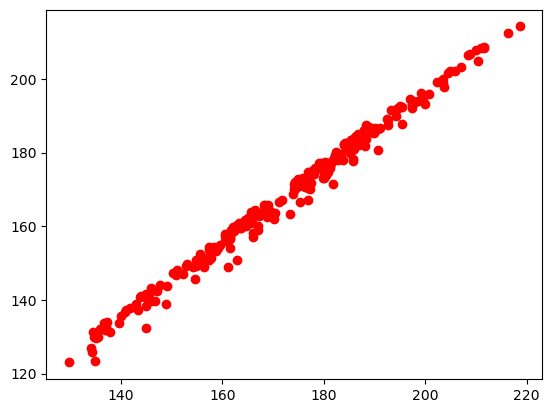

In [8]:
plt.plot('high', 'low', 'ro', data=fb)

In [199]:
fb.head(2)

,date,open,high,low,close,volume,year,month
0,2018-02-01,177.68,181.58,177.55,181.42,18151903,2018,2
1,2018-03-01,181.88,184.78,181.33,184.67,16886563,2018,3


<Axes: xlabel='month', ylabel='volume'>

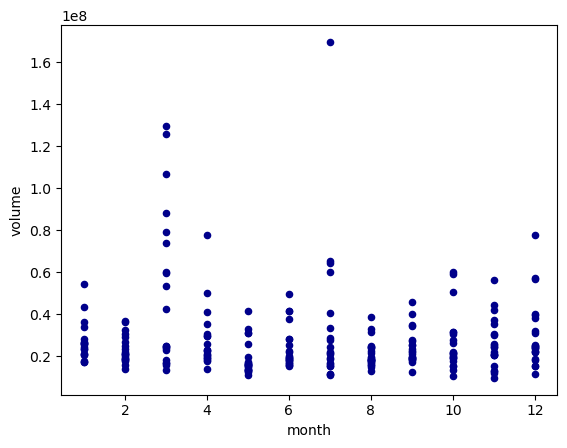

In [200]:
#create a scatter plot for volume per year
fb.plot.scatter(x='month', y='volume', c='DarkBlue')

# Visualizing relationships between variables
Scatter plots

We make scatter plots to help visualize the relationship between two variables. 
    Creating scatter plots requires we pass in kind='scatter' along with a column for the x-axis and a column for the y-axis:

In [201]:
# create a new column impute new column:
fb['price_change'] = fb["high"]-fb["low"]
fb.head(2)


,date,open,high,low,close,volume,year,month,price_change
0,2018-02-01,177.68,181.58,177.55,181.42,18151903,2018,2,4.03
1,2018-03-01,181.88,184.78,181.33,184.67,16886563,2018,3,3.45


<Axes: title={'center': 'Facebook Daily High - Low vs. Volume Traded'}, xlabel='volume', ylabel='price_change'>

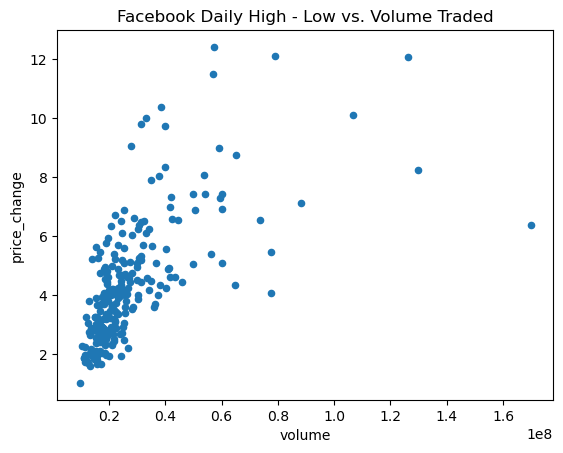

In [202]:
fb.plot(
    kind='scatter', x='volume', y='price_change',
    title='Facebook Daily High - Low vs. Volume Traded'
)

# Counts and frequencies
Bar charts

With pandas, we have the option of using the kind argument or using plot.<kind>(). Let's use plot.bar() here to show the evolution of monthly volume traded in Facebook stock over time:

In [9]:
fb.head(2)

,date,open,high,low,close,volume,year,month
0,2018-02-01,177.68,181.58,177.55,181.42,18151903,2018,2
1,2018-03-01,181.88,184.78,181.33,184.67,16886563,2018,3


<Axes: title={'center': 'Volume Traded'}, xlabel='month'>

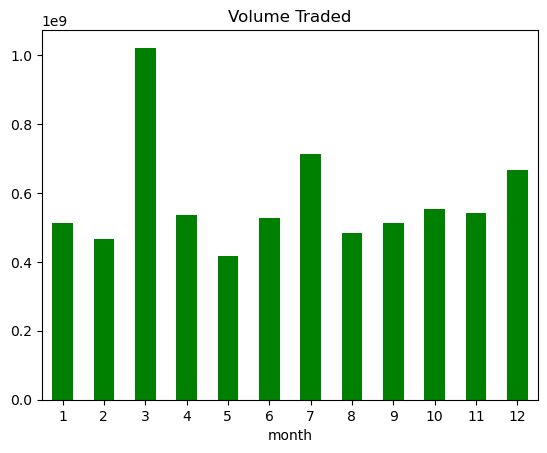

In [203]:
# the below vis is for all the months of 2018
#rot=0 sets the rotation angle of the axis tick labels to 0 degrees, forcing them to display completely horizontally.
fb[fb['year'] == 2018].groupby('month')['volume'].sum().plot.bar(
    color='green',
    rot=0,
    title='Volume Traded'
)

<Axes: title={'center': 'Volume Traded'}, xlabel='month'>

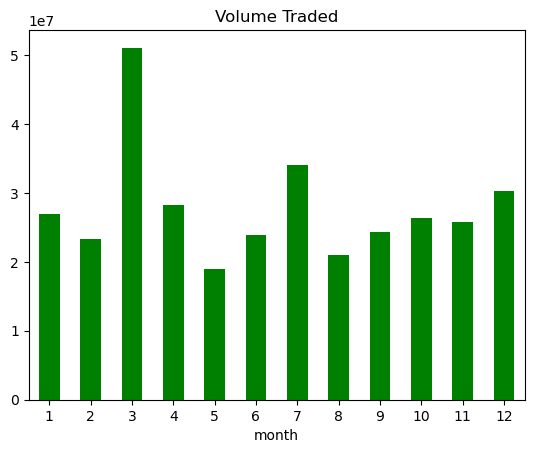

In [204]:
# the below vis is for all the months of 2018
fb[fb['year'] == 2018].groupby('month')['volume'].mean().plot.bar(
    color='green',
    rot=0,
    title='Volume Traded'
)

# Histograms

In [10]:
quakes = pd.read_csv('earthquakes.csv')
quakes.head(2)

,mag,magType,time,place,tsunami,parsed_place
0,0.92,ml,1.540000e+12,"4km ENE of Calimesa, CA",0,California
1,1.35,ml,1.540000e+12,"9km NE of Aguanga, CA",0,California


In [11]:
# convert our date column to DateTime
quakes['time'] = pd.to_datetime(quakes['time'], format='mixed')
quakes['year'] = quakes['time'].dt.year
quakes['month'] = quakes['time'].dt.month
quakes['time_only'] = quakes['time'].dt.time
quakes.head(2)

,mag,magType,time,place,tsunami,parsed_place,year,month,time_only
0,0.92,ml,1970-01-01 00:25:40,"4km ENE of Calimesa, CA",0,California,1970,1,00:25:40
1,1.35,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40


Text(0, 0.5, 'Frequency')

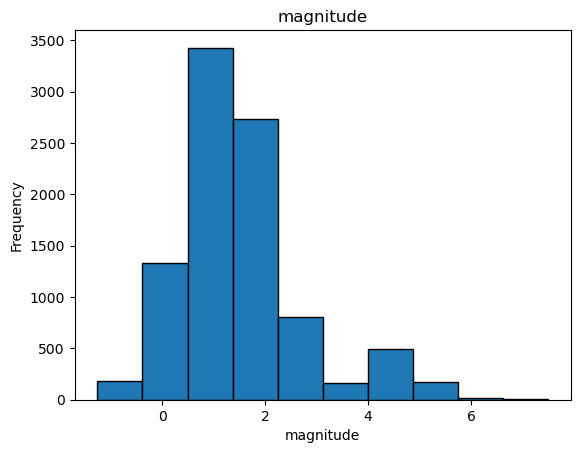

In [207]:
# Quantity histogram
plt.hist(quakes['mag'], edgecolor='black')
plt.title('magnitude')
plt.xlabel('magnitude')
plt.ylabel('Frequency')

# Figure
Top-level object that holds the other plot components.

plt.figure()

# Creating subplots
Simply specify the number of rows and columns to create:

 plt.subplots(1, 2)

Text(0, 0.5, 'Frequency')

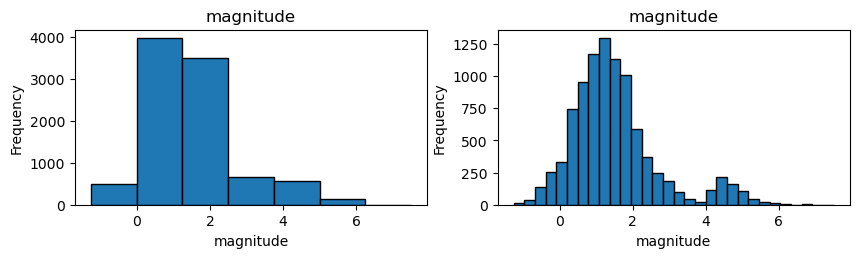

In [208]:
# Create histograms in subplot
plt.figure(figsize=(10, 5))

# plot1
plt.subplot(2, 2, 1)
plt.hist(quakes['mag'], bins=7, edgecolor='black')
plt.title('magnitude')
plt.xlabel('magnitude')
plt.ylabel('Frequency')


# Plot 2
plt.subplot(2, 2, 2)
plt.hist(quakes['mag'], bins=30, edgecolor='black')
plt.title('magnitude')
plt.xlabel('magnitude')
plt.ylabel('Frequency')

# remember we do not call plt.show() here as we run this code in the one of the higher celss therefore it applies for this cell too %matplotlib inline 

Bin size matters <br>
Notice how our assumptions of the distribution of the data can change based on the number of bins (look at the drop between the two highest peaks on the righthand plot):

<Axes: xlabel='parsed_place'>

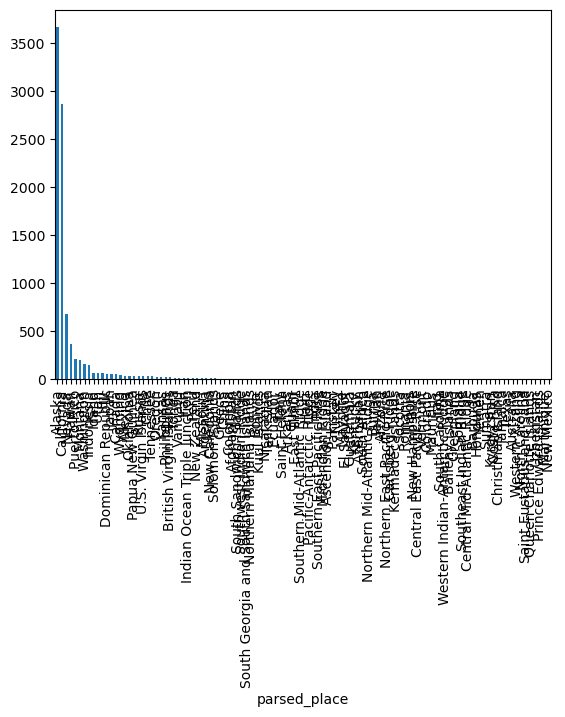

In [209]:
quakes['parsed_place'].value_counts().plot.bar()

We can also change the orientation of the bars. Passing kind='barh' gives us horizontal bars instead of vertical ones. Let's use this to look at the top 15 places for earthquakes in our data:

Text(0.5, 0, 'earthquakes')

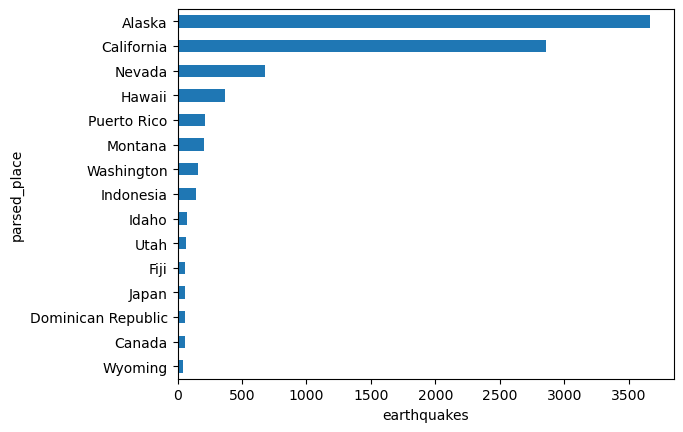

In [210]:
# pay attention to bar versus barh (horizontal)
quakes['parsed_place'].value_counts().head(15).sort_values().plot.barh()
plt.xlabel('earthquakes')


Text(0.5, 0, 'earthquakes')

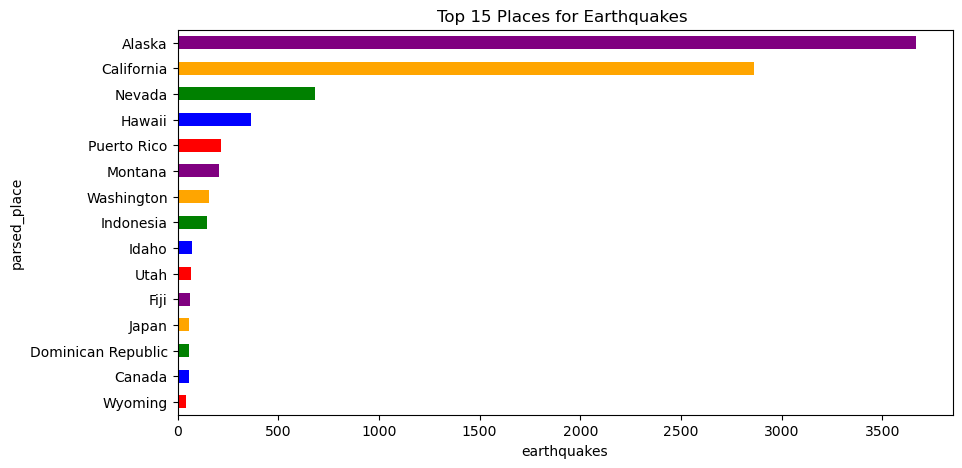

In [211]:
# second method is:
# pay attention to bar versus barh (horizontal) , sort values
quakes['parsed_place'].value_counts().head(15).sort_values().plot(kind='barh', figsize=(10, 5),color=['red', 'blue', 'green', 'orange', 'purple'],
    title='Top 15 Places for Earthquakes ')
plt.xlabel('earthquakes')

We also have data on whether earthquakes were accompanied by tsunamis. Let's see what the top places for tsunamis are:

Text(0.5, 0, 'Number of Tsunamis')

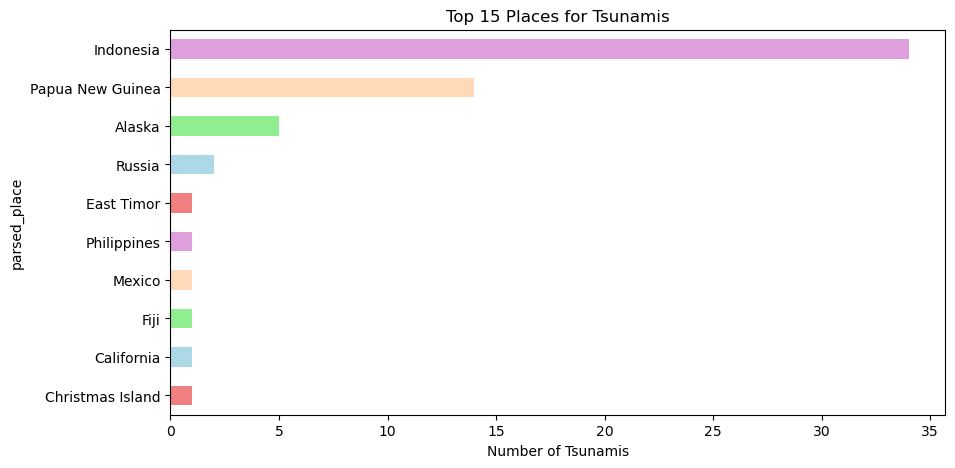

In [212]:
quakes[quakes['tsunami'] == 1]['parsed_place'].value_counts().head(15).sort_values().plot(
    kind='barh',
    figsize=(10, 5),
    color=['lightcoral', 'lightblue', 'lightgreen', 'peachpuff', 'plum'],
    title='Top 15 Places for Tsunamis'
)

plt.xlabel('Number of Tsunamis')

# Saving plots
Use plt.savefig() to save the last created plot. To save a specific Figure object, use its savefig() method.

In [213]:
#Use plt.savefig() to save the last created plot. To save a specific Figure object, use its savefig() method.

fig.savefig('magnitude_frequency.png')

# Handling Data issues


## Duplicate

In [214]:
#test_result is the name of the bucket that holds the data file '2017_18_GT_Results.csv'
quakes.head(2)

,mag,magType,time,place,tsunami,parsed_place,year,month
0,0.92,ml,1970-01-01 00:25:40,"4km ENE of Calimesa, CA",0,California,1970,1
1,1.35,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1


In [215]:
quakes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9333 entries, 0 to 9332
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   mag           9332 non-null   float64       
 1   magType       9331 non-null   object        
 2   time          9333 non-null   datetime64[ns]
 3   place         9333 non-null   object        
 4   tsunami       9333 non-null   int64         
 5   parsed_place  9333 non-null   object        
 6   year          9333 non-null   int32         
 7   month         9333 non-null   int32         
dtypes: datetime64[ns](1), float64(1), int32(2), int64(1), object(3)
memory usage: 510.5+ KB


In [216]:
unique_values = quakes['parsed_place'].unique()
print(unique_values)

['California' 'Dominican Republic' 'Alaska' 'Indonesia' 'Canada'
 'Puerto Rico' 'Montana' 'Nevada' 'Christmas Island' 'Hawaii'
 'Northern Mariana Islands' 'Japan' 'Ecuador' 'Vanuatu' 'Mexico' 'Russia'
 'British Virgin Islands' 'Washington' 'Papua New Guinea' 'Fiji'
 'U.S. Virgin Islands' 'Chile' 'Peru' 'Yemen' 'Guatemala' 'Kansas'
 'Australia' 'Wyoming' 'Kuril Islands' 'Oklahoma' 'Tennessee'
 'Pacific-Antarctic Ridge' 'Utah' 'Colombia' 'Argentina' 'Oregon' 'Greece'
 'Missouri' 'Tajikistan' 'Northern Mid-Atlantic Ridge' 'Sumatra'
 'Solomon Islands' 'Burma' 'Taiwan' 'Nicaragua'
 'South Georgia and South Sandwich Islands' 'Idaho' 'Kyrgyzstan' 'Arizona'
 'Tonga' 'Northern East Pacific Rise' 'South Africa'
 'Southern Mid-Atlantic Ridge' 'Costa Rica' 'China' 'Philippines' 'Haiti'
 'Jamaica' 'Kentucky' 'New Zealand' 'Iran' 'Afghanistan'
 'Southwest Indian Ridge' 'Saint Helena' 'Texas' 'New Caledonia'
 'El Salvador' 'Central Mid-Atlantic Ridge' 'Western Xizang' 'Italy'
 'Mid-Indian Ridge' 'Asc

In [217]:
value_counts = quakes['parsed_place'].value_counts()
print(value_counts)

parsed_place
Alaska                     3665
California                 2862
Nevada                      681
Hawaii                      367
Puerto Rico                 216
                           ... 
Queen Charlotte Islands       1
Uzbekistan                    1
Prince Edward Islands         1
Martinique                    1
New Mexico                    1
Name: count, Length: 110, dtype: int64


In [218]:
quakes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9333 entries, 0 to 9332
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   mag           9332 non-null   float64       
 1   magType       9331 non-null   object        
 2   time          9333 non-null   datetime64[ns]
 3   place         9333 non-null   object        
 4   tsunami       9333 non-null   int64         
 5   parsed_place  9333 non-null   object        
 6   year          9333 non-null   int32         
 7   month         9333 non-null   int32         
dtypes: datetime64[ns](1), float64(1), int32(2), int64(1), object(3)
memory usage: 510.5+ KB


In [14]:
quakes['place'] = quakes['place'].astype('str')

In [15]:
# show duplicates# keep=False marks all occurrences of a duplicated record.
quakes[quakes.duplicated(keep=False)]

,mag,magType,time,place,tsunami,parsed_place,year,month,time_only
0,0.92,ml,1970-01-01 00:25:40,"4km ENE of Calimesa, CA",0,California,1970,1,00:25:40
4,0.44,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40
11,0.50,ml,1970-01-01 00:25:40,"10km NE of Aguanga, CA",0,California,1970,1,00:25:40
13,0.50,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40
20,0.92,ml,1970-01-01 00:25:40,"4km ENE of Calimesa, CA",0,California,1970,1,00:25:40
...,...,...,...,...,...,...,...,...,...
9286,0.62,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40
9293,1.30,ml,1970-01-01 00:25:40,"50km NNE of Yakutat, Alaska",0,Alaska,1970,1,00:25:40
9294,0.44,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40
9296,0.22,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40


In [16]:
quakes[quakes.duplicated(subset=['mag', 'parsed_place', 'tsunami', 'place', 'time_only'], keep=False)]

,mag,magType,time,place,tsunami,parsed_place,year,month,time_only
0,0.92,ml,1970-01-01 00:25:40,"4km ENE of Calimesa, CA",0,California,1970,1,00:25:40
4,0.44,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40
11,0.50,ml,1970-01-01 00:25:40,"10km NE of Aguanga, CA",0,California,1970,1,00:25:40
13,0.50,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40
20,0.92,ml,1970-01-01 00:25:40,"4km ENE of Calimesa, CA",0,California,1970,1,00:25:40
...,...,...,...,...,...,...,...,...,...
9286,0.62,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40
9293,1.30,ml,1970-01-01 00:25:40,"50km NNE of Yakutat, Alaska",0,Alaska,1970,1,00:25:40
9294,0.44,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40
9296,0.22,ml,1970-01-01 00:25:40,"9km NE of Aguanga, CA",0,California,1970,1,00:25:40


In [220]:
# Drop duplicates and keep the first occurrence
quakes = quakes.drop_duplicates()
quakes.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8484 entries, 0 to 9332
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   mag           8483 non-null   float64       
 1   magType       8482 non-null   object        
 2   time          8484 non-null   datetime64[ns]
 3   place         8484 non-null   object        
 4   tsunami       8484 non-null   int64         
 5   parsed_place  8484 non-null   object        
 6   year          8484 non-null   int32         
 7   month         8484 non-null   int32         
dtypes: datetime64[ns](1), float64(1), int32(2), int64(1), object(3)
memory usage: 530.2+ KB


In [221]:
# to check there is no remaining of duplicates: 
quakes[quakes.duplicated(keep=False)]

,mag,magType,time,place,tsunami,parsed_place,year,month


## Drop_duplicates consider:

In [222]:
# Product Information in the below code I creates a dataframe to show you an example, you do not need to create a datafarme for any of your assessments
product = {
    'Product ID': [1, 2, 3, 4, 5],
    'Product Name': ['iPhone X', 'iPhone 11', 'iPhone 12', 'iPhone 13', 'iPhone X'],
    'Category': ['Smartphones', 'Smartphones', 'Smartphones', 'Smartphones', 'Smartphones']
}
product = pd.DataFrame(product)
product

,Product ID,Product Name,Category
0,1,iPhone X,Smartphones
1,2,iPhone 11,Smartphones
2,3,iPhone 12,Smartphones
3,4,iPhone 13,Smartphones
4,5,iPhone X,Smartphones


In [223]:
# show duplicates# keep=False marks all occurrences of a duplicated record.
product[product.duplicated(keep=False)]

,Product ID,Product Name,Category


the above code could not find duplciates the reason is that product.duplicated find duplicated records when values in all the columns are duplciated, however, column ID here is just a unique identifier and does not have meaningful value whne it comes to duploication, therefore, we need to narrow the search to meaningful columns

In [224]:
product[product.duplicated(subset=['Category', 'Product Name'], keep=False)]

,Product ID,Product Name,Category
0,1,iPhone X,Smartphones
4,5,iPhone X,Smartphones


In [225]:
# Drop duplicates and keep the first occurrence
product = product.drop_duplicates(subset=['Category', 'Product Name'])

In [226]:
product

,Product ID,Product Name,Category
0,1,iPhone X,Smartphones
1,2,iPhone 11,Smartphones
2,3,iPhone 12,Smartphones
3,4,iPhone 13,Smartphones


# Finding Missing Values
isnull().sum() indicate total missing values in each column

In [227]:
missing_count = product.isnull().sum()
missing_count

Product ID      0
Product Name    0
Category        0
dtype: int64

In [228]:
missing_count = fb.isnull().sum()
missing_count

date            0
open            0
high            0
low             0
close           0
volume          0
year            0
month           0
price_change    0
dtype: int64

In [17]:
missing_count = quakes.isnull().sum()
missing_count

mag             1
magType         2
time            0
place           0
tsunami         0
parsed_place    0
year            0
month           0
time_only       0
dtype: int64

# soemtime, Pandas does not treat empty strings as missing.
to fix this issue, when reading the files :

In [230]:
# Replace any empty strings with NaN - sometimes we have N/A or NA that mean null, in those cases, there should be include
quakes = quakes.replace(['', ' ', 'NaN', 'null', 'NULL', 'None'], pd.NA)
quakes.isnull().sum()  # now catches both NaN and former empty strings

mag             1
magType         2
time            0
place           0
tsunami         0
parsed_place    0
year            0
month           0
dtype: int64

# important! Save the clean file back to your home directory

In [231]:
#save the files back into directory/folder
quakes.to_csv('quakes_clean.csv', index=False)

In [232]:
# next session we will talk about outliers, skewness and how to fix missing values using imputation or drop